# Tarea: Ajuste de Superficies con Machine Learning

En este trabajo, cada grupo tiene un conjunto de datos único con valores de $x_1$, $x_2$ y $f(x_1, x_2)$. Su objetivo es encontrar los parámetros de dos modelos de superficies que minimicen el error de ajuste a los datos mediante un enfoque de **Machine Learning**. Debe seguir los pasos de un proyecto de ML, tal como lo vimos en clases, considere el set de datos de su propio grupo.

Debe considerar las siguientes hipótesis:

## Descripción de los Modelos

Los tres modelos de superficie que deben probar son los siguientes:

**Modelo A:**
$f_A(x_1, x_2) = w_0 + w_{01} x_1 + w_{02} x_2$

**Modelo B:**
$f_B(x_1, x_2) = w_0 + w_{01} x_1 + w_{02} x_2 + w_{11} x_1^2 + w_{22} x_2^2 + w_{12} x_1 x_2$

**Modelo C:**
$f_C(x_1, x_2) = w_0 + w_{01} x_1 + w_{02} x_2 + w_{11} x_1^2 + w_{22} x_2^2 + w_{12} x_1 x_2 + w_{111} x_1^3 + w_{222} x_2^3$

## Objetivo

Para cada modelo, deben encontrar los parámetros que minimicen el error cuadrático medio (MSE) entre las predicciones de cada modelo y los valores reales de $f(x_1, x_2)$ en su conjunto de datos.

## Instrucciones

1. **Importación de Datos**: Cada grupo debe cargar su propio conjunto de datos que contiene valores para $x_1$, $x_2$ y $f(x_1, x_2)$. Quizá es recomendable que le den una mirada a los datos y ver como se comportan, para que se hagan una idea de las formas.
2. **Implementación de los Modelos**: encuentren los parámetros de ambos modelos usando un enfoque de *Machine Learning*, específicamente utilicen una minimización de errores cuadráticos (regresión lineal).
3. **Optimización en ML**: Utilicen descenso de gradiente para encontrar los parámetros $w_0$, $w_{01}$, $w_{02}$, etc., que minimicen el error. Es muy importante, en el punto 2 y 3, que consideren que dice con enfoque de *Machine Learning* por lo que deben considerar esto para saber hasta cuando se debe iterar con el método, deben definir conjunto de entrenamiento y de testeo.
4. **Evaluación del Error en ML**: Calcular el error cuadrático medio (MSE) para cada modelo y determinar cuál modelo ajusta mejor los datos.
5. **Comparación de Modelos**: Comparen los resultados obtenidos con ambos modelos y expliquen cuál modelo es más adecuado para su conjunto de datos y por qué.

## Espacios de Trabajo

A continuación, se proporcionan bloques de código donde pueden implementar los pasos descritos anteriormente.


### 1. Importación de Librerías y Datos

Comiencen importando las librerías necesarias y cargando su conjunto de datos.

In [138]:
""" Instalación de Librerías """
!pip install numpy
!pip install scikit-learn

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Vista de los datos para ver como estan presentados: 
    id         x1         x2            y
0   1  36.026675  26.957774   964.359446
1   2  47.084866  33.942681  1495.833729
2   3  26.435368   8.050369   372.448568
3   4  41.386123  17.903661   606.615661
4   5  40.419733  44.331060  1542.157970
Dimensiones del conjunto de datos: (200, 4)



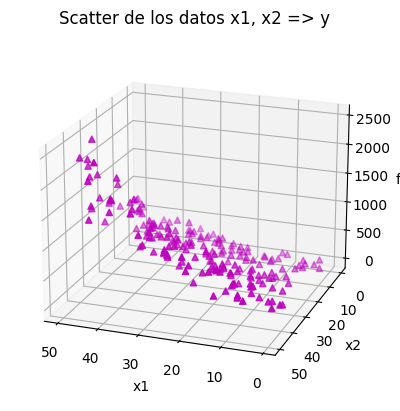


Dimensiones conjunto x de entrenamiento: (160, 3)
Dimensiones Conjuntos x de prueba: (40, 3)
Dimensiones conjunto y de entrenamiento: (160, 1)
Dimensiones conjunto y de prueba: (40, 1)


In [139]:
""" Importar las librerías """
import numpy as np
import pandas as pd
from google.colab import drive
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler

"""Importar datos guardados en el drive"""
# Montar Google Drive
drive.mount('/content/drive')

# Cargar el archivo
file_path = '/content/drive/MyDrive/TareasDeepLearningG3/Tarea1/Datos_T1DL202420_Grupo3.xlsx'
data = pd.read_excel(file_path)

# Revisar las primeras líneas del archivo, las dimensiones de este y extraer las columnas
print(f'\nVista de los datos para ver como estan presentados: \n {data.head()}')
# Revisar las dimensiones del archivo
print(f'Dimensiones del conjunto de datos: {data.shape}\n')
# Guardar cada columna en una variable
x1 = data['x1'].values
x2 = data['x2'].values
y = data['y'].values

""" Antes de separar los datos es bueno tener una noción de como se mueven los datos por eso se grafica"""
# Realizar el environment (figura) para graficar
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
# Graficar
ax.scatter(x1, x2, y, c='m', marker='^')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('f')
# Configuraciones de vista y título del gráfico
ax.view_init(azim=110, elev=20) #rota el gráfico alrededor del eje vertical y elevar la visión.
plt.title(f'Scatter de los datos x1, x2 => y')
plt.show()  # Mostrar el gráfico

#Reformateo de y
y = y.reshape(len(y),1)
# Columna de unos ayuda a la creación del peso w_0 que no depende de los datos, el sesgo que siempre esta.
ones = np.ones((len(y),1))
# Realizar matriz con las columnas de unos, x1 y x2.
x = np.column_stack((ones, x1,x2))
# Separar los datos en train (80%) y test(20%)
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.8, test_size=0.2, random_state=30)

print(f'\nDimensiones conjunto x de entrenamiento: {x_train.shape}')
print(f'Dimensiones Conjuntos x de prueba: {x_test.shape}')
print(f'Dimensiones conjunto y de entrenamiento: {y_train.shape}')
print(f'Dimensiones conjunto y de prueba: {y_test.shape}')

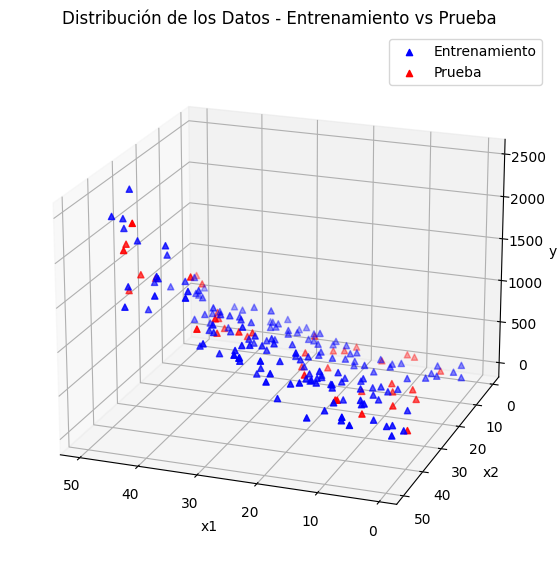

In [140]:
"""
Scatter de los datos entrenamiento y prueba
con el fin de ver que tan aleatorio es la división de los datos
"""
# Realizar la figura
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
# Graficar
ax.scatter(x_train[:, 1], x_train[:, 2], y_train, c='b', marker='^', label='Entrenamiento')
ax.scatter(x_test[:, 1], x_test[:, 2], y_test, c='r', marker='^', label='Prueba')

ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('y')

# Ajustar la vista del gráfico
ax.view_init(azim=110, elev=20)

# Título del gráfico
plt.title(f'Distribución de los Datos - Entrenamiento vs Prueba')
# Mostrar leyenda
plt.legend()
# Mostrar gráfico
plt.show()

### 2. Implementación del Modelo A

Implementen el modelo lineal $f_A(x1, x2)$ y encuentren los parámetros óptimos.
Dele una mirada a los archivos provistos en las clases de laboratorio, le será de utilidad para encontrar el gradiente del error, y por ende poder implementar el método del gradiente.


Los pesos son (w0, w1, w2): 
[[-0.12026419]
 [16.28965792]
 [11.42108536]]


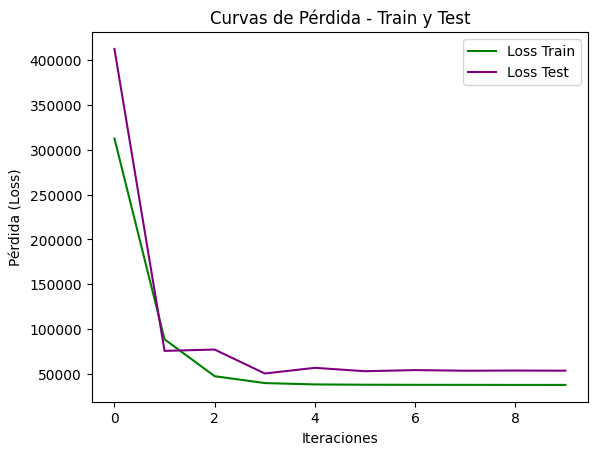

' NO TOCAR EL CÓDIGO ANTERIOR PORFAVOR !!!!! '

In [141]:
"""  Modelo A
w0 + w01*x1 + w02*x2
"""
def f_loss(deltas,n):
  # Hay que usar este forma del MSE (F_loss) ya que los deltas los estamos utilizando normalizados según el conjunto de datos en el que trabajamos
  loss = np.sum(deltas ** 2) / (2 / n)
  return loss

def gradiente_descendiente(x_train, x_test, y_train, y_test, w, n_train, n_test, lr, n_iter):
  # Realizar varias repeticiones para calcular los pesos
  for i in range (n_iter):
    # y estimado => producto punto entre x y w
    y_gorro_train = np.dot(x_train,w) # (160,3) * (3,1) = (160,1)
    y_gorro_test = np.dot(x_test,w) # (40,3) * (3,1) = (40,1)
    # error entre los y normalizado
    deltas_train = (y_gorro_train - y_train) / n_train
    deltas_test = (y_gorro_test - y_test) / n_test
    # Calcular f_loss para cada conjunto de datos
    loss_train[i] = f_loss(deltas_train, n_train)
    loss_test[i] = f_loss(deltas_test, n_test)
    # Aplicar el modelos gradiente descendiente para calcular w
    w = w - (lr * np.dot(x_train.T, deltas_train))
  return w, loss_train, loss_test, y_gorro_test

n_train = len(y_train)
n_test = len(y_test)
# Hiper parámetros
n_iter = 10
lr = 0.001

# Definir los f_loss de prueba y entremamineto como matriz de 1s para ponerlos en el ciclo for y ahí calculando los valores.
loss_train = np.zeros(n_iter)
loss_test = np.zeros(n_iter)
# 3 pesos en el modelo 1
w = np.zeros((3,1))
w, loss_train1, loss_test1, y_gorro_test1 = gradiente_descendiente(x_train, x_test, y_train, y_test, w, n_train, n_test, lr, n_iter)
print(f'Los pesos son (w0, w1, w2): \n{w}')

# Graficar los errores
plt.plot(loss_train1, label='Loss Train', color='green')
plt.plot(loss_test1, label='Loss Test', color='purple')

plt.title(f'Curvas de Pérdida - Train y Test')
plt.xlabel(f'Iteraciones')
plt.ylabel(f'Pérdida (Loss)')

plt.legend()
plt.show()

""" NO TOCAR EL CÓDIGO ANTERIOR PORFAVOR !!!!! """

### 3. Implementación del Modelo B

Implementen el modelo cuadrático $f_B(x1, x2)$ y encuentren los parámetros óptimos.
Dele una mirada a los archivos provistos en las clases de laboratorio, le será de utilidad para encontrar el gradiente del error, y por ende poder implementar el método del gradiente.

Pesos finales para el modelo B:
 [[1.89698194e-04]
 [8.13163862e-03]
 [6.74293160e-03]
 [3.41562776e-01]
 [2.23139321e-01]
 [3.14411895e-01]]


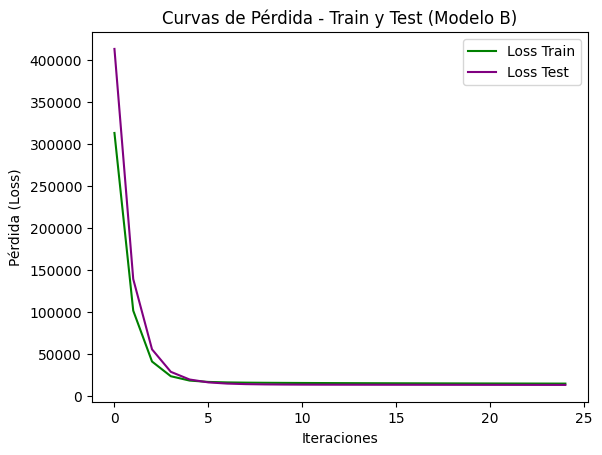

In [142]:
"""" Empieza el modelo B
fB(x1,x2)= w0 + w01*x1 + w02*x2 + w11*x1**2 + w22*x2**2 +  w12*x1*x2
"""
# Crear las características para el modelo 2
x1_2 = x1 ** 2
x2_2 = x2 ** 2
x1_x2 = x1 * x2

# Columna de unos ayuda a la creación del peso w_0 que no depende de los datos, el sesgo que siempre esta.
ones = np.ones((len(y), 1))
# Reformar el x con los parametros para el modelo 2
x = np.column_stack((ones, x1, x2, x1_2, x2_2, x1_x2))
# Separar los datos en train y test
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.8, test_size=0.2, random_state=30)

def f_loss(deltas,n):
  # Hay que usar este forma del MSE (F_loss) ya que los deltas los estamos utilizando normalizados según el conjunto de datos en el que trabajamos
  loss = np.sum(deltas ** 2) / (2 / n)
  return loss

# Gradiente descendente
def gradiente_descendiente(x_train, x_test, y_train, y_test, w, n_train, n_test, lr, n_iter):
  # Realizar varias repeticiones para calcular los pesos
  for i in range (n_iter):
    # y estimado => producto punto entre x y w
    y_gorro_train = np.dot(x_train,w) # (160, 6) * (6,1) = (160,1)
    y_gorro_test = np.dot(x_test,w) # (40,6) * (6,1) = (40,1)
    # error entre los y normalizado
    deltas_train = (y_gorro_train - y_train) / n_train
    deltas_test = (y_gorro_test - y_test) / n_test
    # Calcular f_loss para cada conjunto de datos
    loss_train[i] = f_loss(deltas_train, n_train)
    loss_test[i] = f_loss(deltas_test, n_test)
    # Aplicar el modelos gradiente descendiente para calcular w
    w = w - (lr * np.dot(x_train.T, deltas_train))
  return w, loss_train, loss_test, y_gorro_test

# Hyperparámetros
n_iter = 25
lr = 0.0000002
# Cantidad de elementos
n_train = len(y_train) #160
n_test = len(y_test) #40

# Inicializar pérdidas y pesos
loss_train = np.zeros(n_iter)
loss_test = np.zeros(n_iter)
w = w = np.zeros((6,1)) # Se esperan 6 pesos para el modelo B

# Entrenar el modelo
w, loss_train2, loss_test2, y_gorro_test2 = gradiente_descendiente(x_train, x_test, y_train, y_test, w, n_train, n_test, lr, n_iter)

# Mostrar los pesos finales
print(f'Pesos finales para el modelo B:\n {w}')

# Graficar las curvas de pérdida
plt.plot(loss_train2, label='Loss Train', color='green')
plt.plot(loss_test2, label='Loss Test', color='purple')
plt.title(f'Curvas de Pérdida - Train y Test (Modelo B)')
plt.xlabel(f'Iteraciones')
plt.ylabel(f'Pérdida (Loss)')
plt.legend()
plt.show()

### 4. Implementación del Modelo C

Implementen el modelo cuadrático $f_C(x1, x2)$ y encuentren los parámetros óptimos.
Dele una mirada a los archivos provistos en las clases de laboratorio, le será de utilidad para encontrar el gradiente del error, y por ende poder implementar el método del gradiente.

Pesos finales para el modelo C:
 [[2.47525240e-07]
 [7.87841431e-06]
 [7.35973521e-06]
 [2.80715495e-04]
 [2.44009155e-04]
 [2.44086047e-04]
 [1.08563954e-02]
 [8.63921399e-03]]


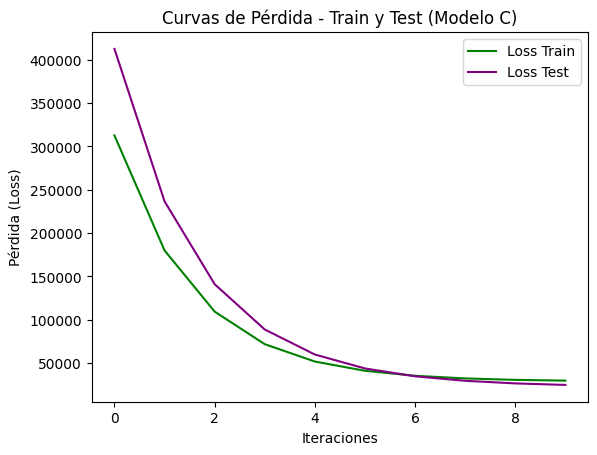

In [143]:
"""" Empieza el modelo C
w0 + w01*x1+ w02*x2 + w11*x1**2 + w22*x2**2 + w12*x1*x2 + w111*x1**3 + w222*x2**3
"""
# Crear las características para el modelo C adicionales (Se tuvo que haber corrido del modelo B)
x1_3 = x1 ** 3
x2_3 = x2 ** 3

# Columna de unos ayuda a la creación del peso w_0 que no depende de los datos, el sesgo que siempre esta.
ones = np.ones((len(y), 1))
# Reformar el x con los parametros para el modelo C
x = np.column_stack((ones, x1, x2, x1_2, x2_2, x1_x2, x1_3, x2_3))

# Separar los datos en train y test
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.8, test_size=0.2, random_state=30)


def f_loss(deltas, n):
  # Hay que usar este forma del MSE (F_loss) ya que los deltas los estamos utilizando normalizados según el conjunto de datos en el que trabajamos
  loss = np.sum(deltas ** 2) / (2 / n)
  return loss

# Gradiente descendente
def gradiente_descendiente(x_train, x_test, y_train, y_test, w, n_train, n_test, lr, n_iter):
  for i in range (n_iter):
    # y estimado => producto punto entre x y w
    y_gorro_train = np.dot(x_train,w) # (160, 6) * (6,1) = (160,1)
    y_gorro_test = np.dot(x_test,w) # (40,6) * (6,1) = (40,1)
    # error entre los y normalizado
    deltas_train = (y_gorro_train - y_train) / n_train
    deltas_test = (y_gorro_test - y_test) / n_test
    # Calcular f_loss para cada conjunto de datos
    loss_train[i] = f_loss(deltas_train, n_train)
    loss_test[i] = f_loss(deltas_test, n_test)
    # Aplicar el modelos gradiente descendiente para calcular w
    w = w - (lr * np.dot(x_train.T, deltas_train))
  return w, loss_train, loss_test, y_gorro_test


# Hyperparámetros
n_iter = 10
lr = 0.0000000001
# Cantidad de elementos, Si se corre los anteriores no hay necesidad de correr estas 2 líneas
#n_train = len(y_train)
#n_test = len(y_test)

# Reiniciar las pérdidas y pesos
loss_train = np.zeros(n_iter)
loss_test = np.zeros(n_iter)
w = np.zeros((8, 1))  # Se esperan 8 pesos para el modelo C

# Entrenar el modelo
w, loss_train3, loss_test3, y_gorro_test3 = gradiente_descendiente(x_train, x_test, y_train, y_test, w, n_train, n_test, lr, n_iter)

# Mostrar los pesos finales
print(f'Pesos finales para el modelo C:\n {w}')

# Graficar las curvas de pérdida
plt.plot(loss_train3, label='Loss Train', color='green')
plt.plot(loss_test3, label='Loss Test', color='purple')
plt.title('Curvas de Pérdida - Train y Test (Modelo C)')
plt.xlabel('Iteraciones')
plt.ylabel('Pérdida (Loss)')
plt.legend()
plt.show()

### 5. Comparación de Resultados

Comparen los errores obtenidos y discutan cuál modelo se ajusta mejor a su conjunto de datos.
* Incluya su discusión
* Incluya sus análisis numéricos y/o gráficos que decida utilizar.

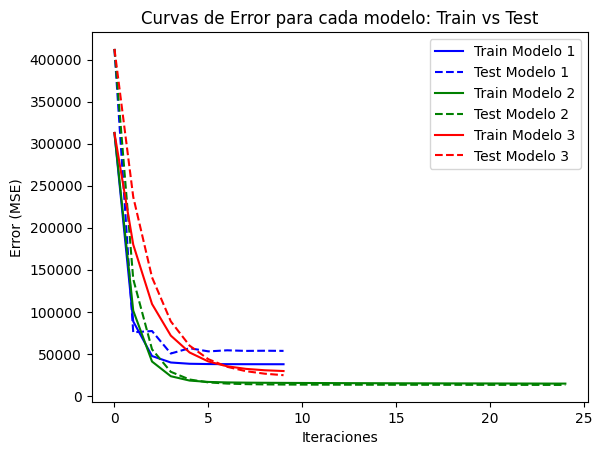

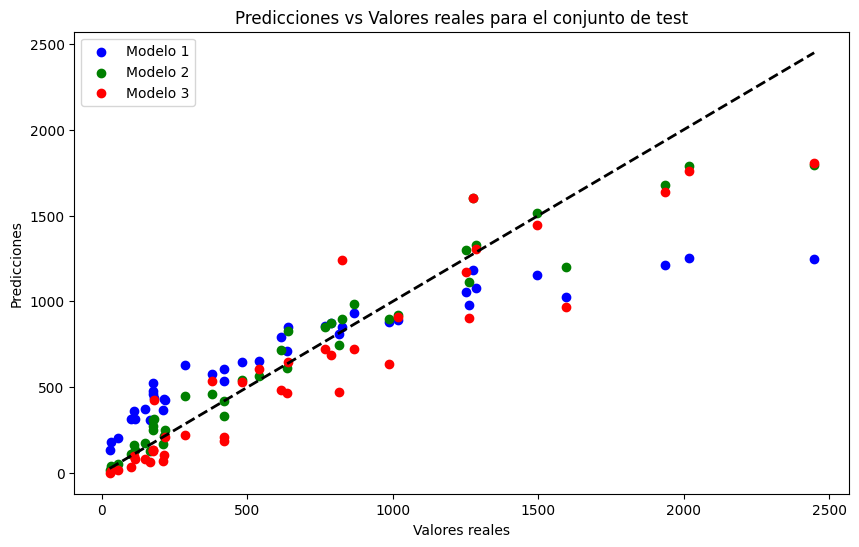

In [144]:
""" Código para comparar los resultados y mostrar conclusiones """
# Gráfico que compare todos los test y train para cada modelo
plt.plot(loss_train1, label='Train Modelo 1', color='blue')
plt.plot(loss_test1, label='Test Modelo 1', color='blue', linestyle='--')

plt.plot(loss_train2, label='Train Modelo 2', color='green')
plt.plot(loss_test2, label='Test Modelo 2', color='green', linestyle='--')

plt.plot(loss_train3, label='Train Modelo 3', color='red')
plt.plot(loss_test3, label='Test Modelo 3', color='red', linestyle='--')

plt.title('Curvas de Error para cada modelo: Train vs Test')
plt.xlabel('Iteraciones')
plt.ylabel('Error (MSE)')
plt.legend()
plt.show()

# Gráfico de Predicciones vs Valores reales para el conjunto de test
plt.figure(figsize=(10,6))
plt.scatter(y_test, y_gorro_test1, color='blue', label='Modelo 1')
plt.scatter(y_test, y_gorro_test2, color='green', label='Modelo 2')
plt.scatter(y_test, y_gorro_test3, color='red', label='Modelo 3')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)  # línea ideal
plt.xlabel('Valores reales')
plt.ylabel('Predicciones')
plt.title('Predicciones vs Valores reales para el conjunto de test')
plt.legend()
plt.show()

**Gráfico 1**

---



El análisis se centra en la evaluación de tres modelos de aprendizaje automático, cada uno con diferentes configuraciones de tasa de aprendizaje (learning rate) y número de iteraciones, lo que influye en su rendimiento y capacidad de convergencia.

Modelo 1 (azul) utiliza 10 iteraciones y un learning rate de 0.001. Este modelo muestra una rápida convergencia, con una reducción significativa en el error tanto en el conjunto de entrenamiento como en el de test. Sin embargo, a pesar de su rapidez, el error final es superior al del Modelo 2, lo que sugiere que un aprendizaje acelerado puede no llevar a la solución más óptima.

Modelo 2 (verde), con 25 iteraciones y un learning rate de 0.0000002, presenta una curva de error más suave. Aunque su proceso de convergencia es más lento, logra un error final más bajo, indicando que un learning rate bajo puede ser beneficioso para alcanzar soluciones más precisas y evitar grandes saltos en el espacio de búsqueda.

Modelo 3 (rojo), que opera con un learning rate extremadamente bajo de 0.0000000001 y solo 10 iteraciones, no logra una convergencia adecuada. Sus curvas de error permanecen elevadas, lo que indica que el modelo apenas ha comenzado a aprender. Esto resalta la importancia de un balance adecuado entre la tasa de aprendizaje y el número de iteraciones.

En términos de generalización, los tres modelos muestran curvas de entrenamiento y test relativamente cercanas, lo que sugiere que no están sobreajustando significativamente. Sin embargo, el Modelo 1 muestra una ligera separación entre estas curvas, lo que podría indicar un riesgo de sobreajuste si se realizan más iteraciones. El Modelo 2 se destaca por tener la mejor generalización, mientras que el Modelo 3 aún no ha convergido y presenta errores altos.

Finalmente, se recomienda que el Modelo 1 considere una leve reducción en su learning rate o un incremento en el número de iteraciones para mejorar su rendimiento. El Modelo 2 parece estar bien equilibrado, aunque podría beneficiarse de un ajuste del learning rate para acelerar su convergencia sin comprometer la precisión. Por otro lado, el Modelo 3 necesita un aumento en el número de iteraciones o un aprendizaje más alto para lograr un desempeño eficiente.

En conclusión, el Modelo 2 se presenta como el mejor equilibrando precisión y capacidad de generalización, mientras que el Modelo 1 podría mejorar con ajustes finos y el Modelo 3 está subentrenado debido a su configuración actual

**Gráfico 2**

---

Modelo 1 (azul): presenta algunas predicciones que se desvían notablemente de la línea ideal, especialmente en el rango superior, donde se observan subestimaciones de los valores reales altos. Varios puntos se sitúan por debajo de la línea ideal, lo que indica que este modelo no logra captar adecuadamente la relación entre las variables cuando los valores reales son elevados. En contraste, en el rango bajo (cerca de 0-500), las predicciones parecen estar más alineadas con los valores reales.

Modelo 2 (verde): muestra un rendimiento más equilibrado en comparación con el Modelo 1. Muchos de los puntos verdes están más cercanos a la línea ideal, lo que sugiere una mejor precisión. Sin embargo, aún se observan algunas predicciones incorrectas en los valores altos, aunque la dispersión es menor que en el Modelo 1. Para los valores bajos y moderados, las predicciones están razonablemente alineadas con los valores reales.

Modelo 3 (rojo): destaca por tener varios puntos más cercanos a la línea ideal en comparación con los otros modelos, especialmente en los rangos bajo y medio. No obstante, también presenta una subestimación significativa de las predicciones en los valores altos, con muchos puntos rojos situados por debajo de la línea en el rango de 1000 a 2500. Aunque este modelo se desempeña mejor en los valores bajos y medianos, no logra capturar adecuadamente las predicciones para los valores altos.

Conclusiones: el modelo 1 parece tener el peor desempeño, evidenciado por una mayor dispersión en las predicciones y una clara tendencia a subestimar los valores altos. El modelo 2 muestra una mejora respecto al modelo 1, con predicciones más consistentes en los rangos bajo y medio, pero aún presenta dificultades con los valores altos. Por su parte, el modelo 3 se posiciona como el mejor en general para los valores bajos y medianos, aunque enfrenta un problema considerable al subestimar los valores altos.

Recomendaciones: para mejorar la capacidad de los modelos en la predicción de valores altos, se sugiere realizar ajustes en los hiperparámetros o modificar la arquitectura de los modelos. Además, podría ser beneficioso explorar enfoques de regresión no lineal, dado que los tres modelos enfrentan dificultades con los valores altos. En resumen, aunque el Modelo 3 parece tener el mejor desempeño general, ninguno de los modelos logra predecir adecuadamente los valores altos, lo que indica un significativo margen de mejora.